## **Shallow water equations**

In [39]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [40]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit, evaluate
from src.mSHRED.mSHRED import mSHRED
from src.utils import plot_training_curves, evaluate_model

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [41]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


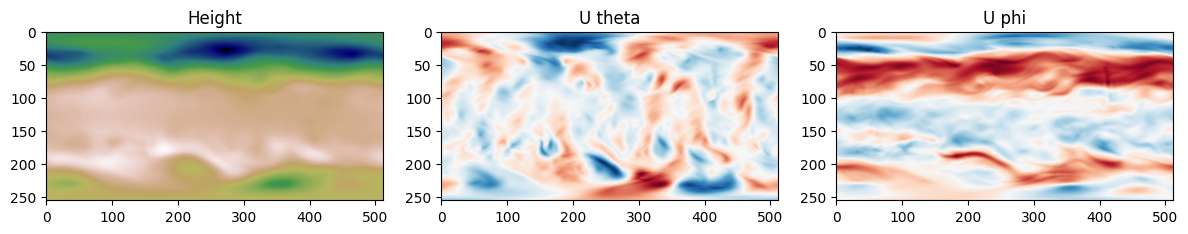

In [42]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

In [43]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[194 466]
 [ 72  52]
 [190 128]
 [152 182]
 [105 508]
 [127 209]
 [183 380]
 [ 47  35]
 [249 106]
 [207 136]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [194 466]): 210 of 1008 steps masked
Short broken sensor 1 (coord [72 52]): 180 of 1008 steps masked
Short broken sensor 2 (coord [190 128]): 180 of 1008 steps masked
Short broken sensor 3 (coord [152 182]): 205 of 1008 steps masked
Long broken sensor  4 (coord [105 508]): steps 33 to 71 masked
Long broken sensor  5 (coord [127 209]): steps 393 to 800 masked
Long broken sensor  6 (coord [183 380]): steps 29 to 909 masked
Long broken sensor  7 (coord [47 35]): steps 239 to 626 masked


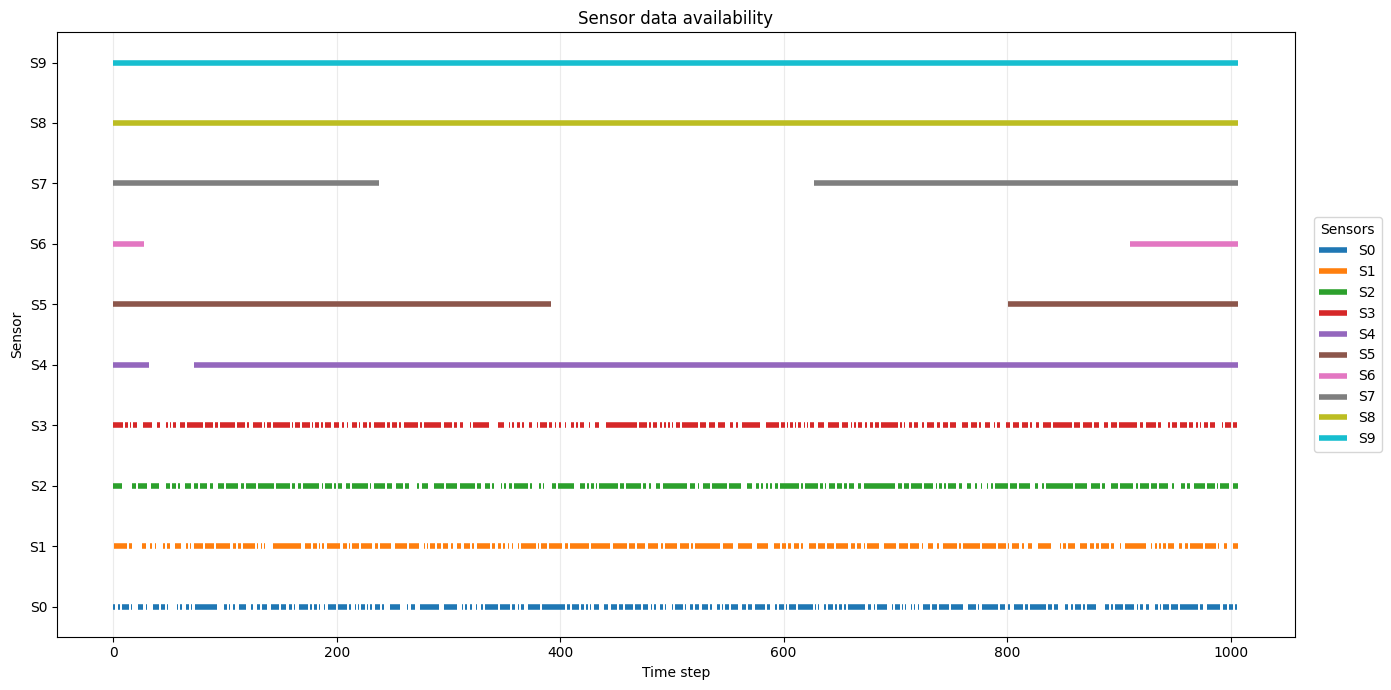

In [44]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, sensor_labels=None):
    """sensor_data: (ntimes, nsensors)"""
    availability = (~torch.isnan(sensor_data)).to(torch.float32).cpu().numpy()
    time          = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")
    plt.title(title_prefix)
    plt.tight_layout()
    plt.show()

plot_data_availability(sensors_data, "Sensor data availability", sensor_labels=np.arange(nsensors))

## Check

## SENSOR extraction

In [45]:
np.random.seed(42)  # For reproducibility

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)

H = np.vstack((H,H))
H = H.reshape(16, -1, 131072)
sensors_data = np.vstack((sensors_data,sensors_data))
sensors_data = sensors_data.reshape(16, -1, 10)

permutation = np.random.permutation(sensors_data.shape[0])
sensors_data = sensors_data[permutation]
H = H[permutation]

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)  

del Utheta, Uphi

Sensors data shape:	 torch.Size([1008, 10])
H shape:		 torch.Size([1008, 131072])
Sensors data shape:	 (16, 126, 10)
H shape:		 (16, 126, 131072)


In [46]:
def plot_reconstruction(
    reconstruction,
    ground_truth,
    Lx,
    Ly,
    field_name="Surface elevation",
    field_unit=None,
    save_path=None,
    dpi=400,
    title_prefix=""
):
    """
    Plot reconstruction, ground truth, and absolute error.

    Parameters
    ----------
    reconstruction : np.ndarray
        Reconstructed field, flattened or already 2D.
    ground_truth : np.ndarray
        Ground-truth field, flattened or already 2D.
    Lx, Ly : int
        Spatial dimensions.
    field_name : str
        Name of the reconstructed field.
    field_unit : str, optional
        Physical unit, e.g. "m".
    save_path : str, optional
        Path where the figure will be saved.
    dpi : int
        Resolution for raster output.
    title_prefix : str
        Prefix for the figure title.
    """

    # Reshape if necessary
    reconstruction = np.asarray(reconstruction).reshape(Lx, Ly)
    ground_truth = np.asarray(ground_truth).reshape(Lx, Ly)

    # Absolute error
    absolute_error = np.abs(reconstruction - ground_truth)

    # Shared scale for reconstruction and ground truth
    vmin = min(reconstruction.min(), ground_truth.min())
    vmax = max(reconstruction.max(), ground_truth.max())

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------
    fig, axes = plt.subplots(
        1, 3,
        figsize=(20, 4),
        constrained_layout=True
    )

    # Reconstruction
    im0 = axes[0].imshow(
        reconstruction,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        aspect="equal"
    )

    axes[0].set_title(
        f"{title_prefix}",
        fontsize=12,
        fontweight="bold"
    )

    # Ground truth
    im1 = axes[1].imshow(
        ground_truth,
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        origin="lower",
        aspect="equal"
    )

    axes[1].set_title(
        "Ground truth",
        fontsize=12,
        fontweight="bold"
    )

    # Absolute error
    im2 = axes[2].imshow(
        absolute_error,
        cmap="magma",
        vmin=0,
        vmax=absolute_error.max(),
        origin="lower",
        aspect="equal"
    )

    axes[2].set_title(
        "Absolute error",
        fontsize=12,
        fontweight="bold"
    )

    # ---------------------------------------------------------
    # Clean axes
    # ---------------------------------------------------------
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])

        for spine in ax.spines.values():
            spine.set_visible(False)

    # ---------------------------------------------------------
    # Colorbars
    # ---------------------------------------------------------
    field_label = field_name
    if field_unit is not None:
        field_label += f" [{field_unit}]"

    cbar01 = fig.colorbar(
        im1,
        ax=axes[:2],
        fraction=0.025,
        pad=0.02
    )
    cbar01.set_label(field_label, fontsize=10)

    cbar2 = fig.colorbar(
        im2,
        ax=axes[2],
        fraction=0.046,
        pad=0.02
    )
    cbar2.set_label(
        f"Absolute error [{field_unit}]" if field_unit else "Absolute error",
        fontsize=10
    )

    plt.show()

In [47]:
ERRORS = []

# DataManager
LAGS = 100

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS = 100

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.1.A): Median imputer

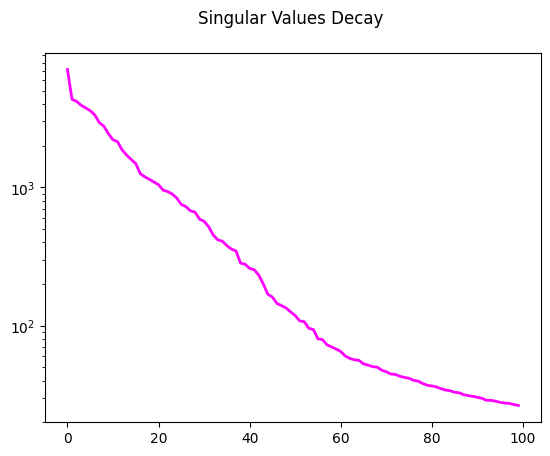

Residual energy of Surface elevation after keeping 100 modes: 0.0299 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])

Input shape for the model: 10
Output shape for the model: 100


In [48]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="median", verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training: 100%|██████████| 200/200 [04:25<00:00,  1.33s/it, Train Loss=0.02258, Val Loss=0.03222, Patience=2, Best Val Loss=0.03222, LR=0.00e+00]

Training completed with best validation loss: 0.0322


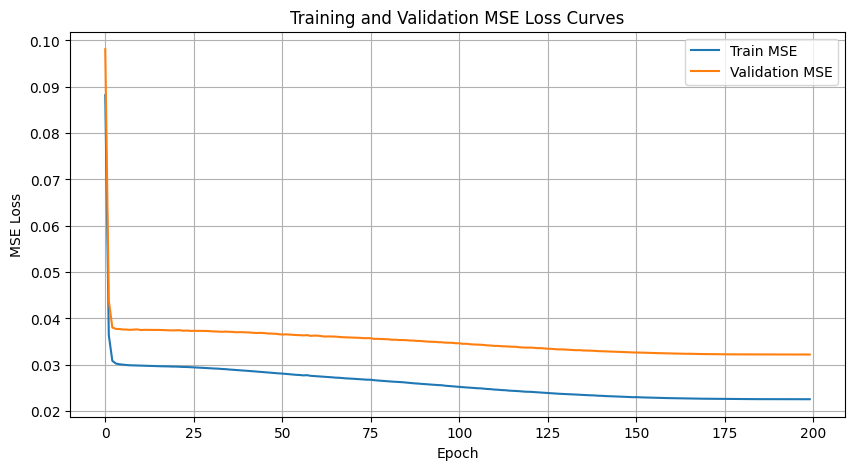

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127


In [49]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.A): median imputation for missing sensors"
)

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

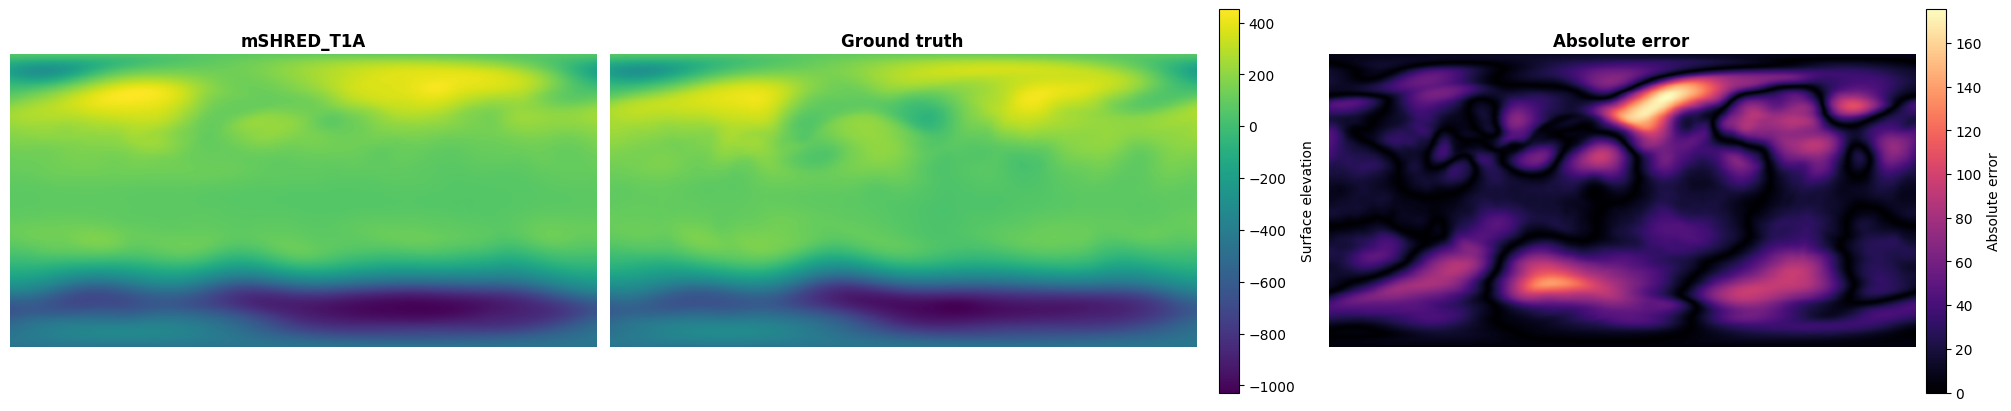

In [ ]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T1A"
)

del train_dataset, val_dataset, test_dataset

## (T.1.B): Mean imputer

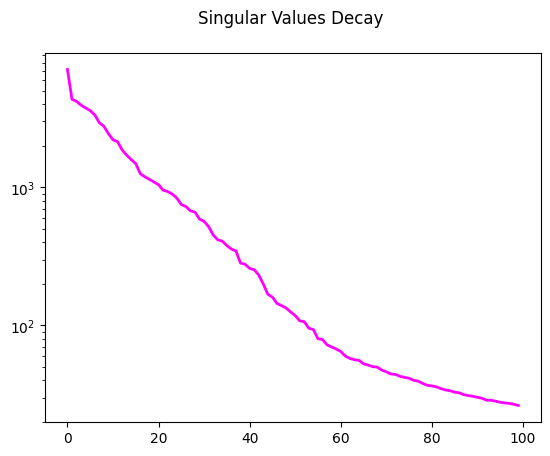

Residual energy of Surface elevation after keeping 100 modes: 0.0299 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])

Input shape for the model: 10
Output shape for the model: 100


In [51]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="mean", verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training: 100%|██████████| 200/200 [02:39<00:00,  1.25it/s, Train Loss=0.02160, Val Loss=0.03029, Patience=0, Best Val Loss=0.03029, LR=0.00e+00]

Training completed with best validation loss: 0.0303


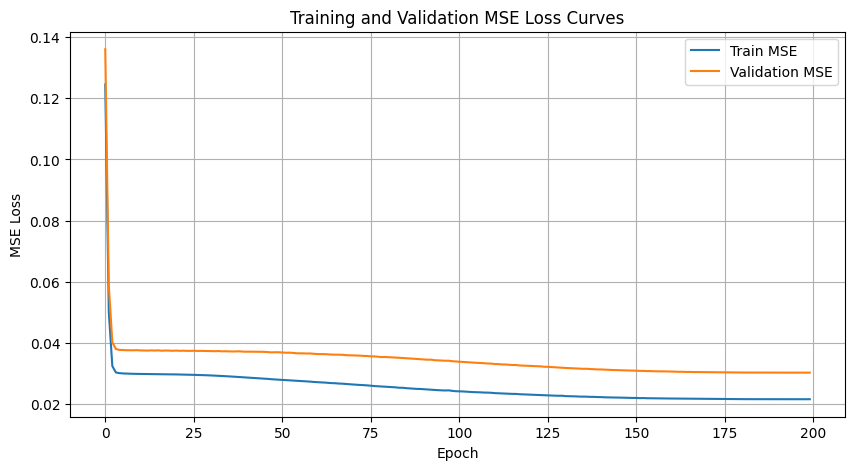

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001


In [52]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.B): mean imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

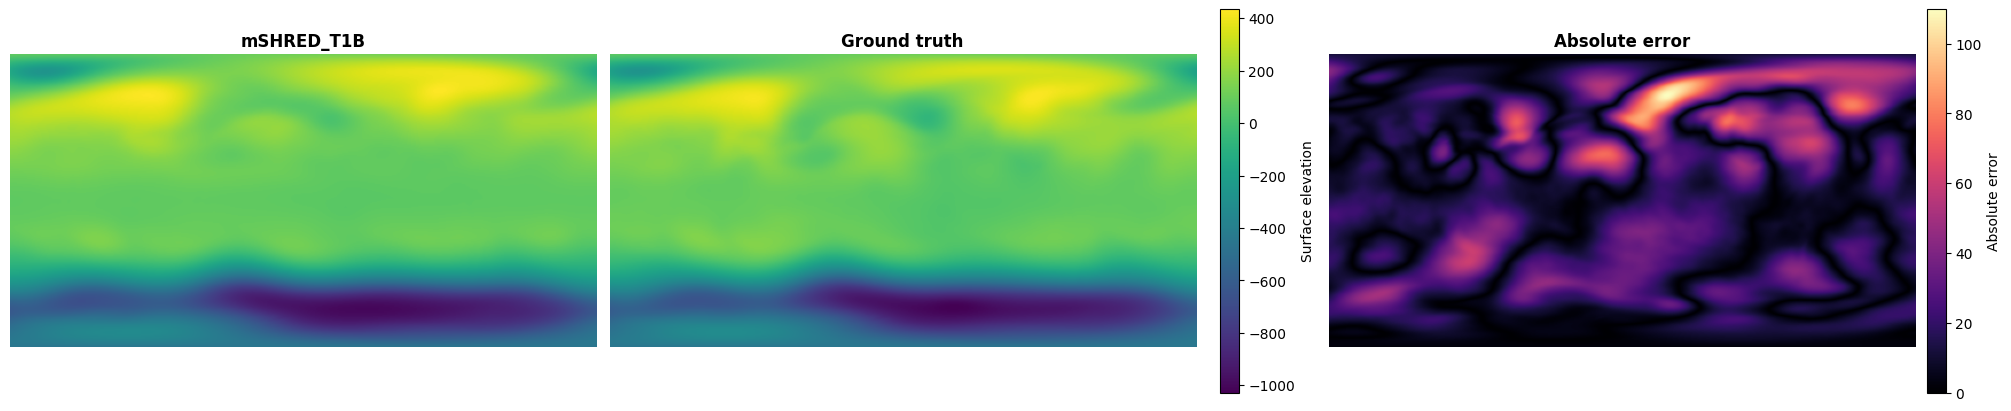

In [53]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T1B"
)
del train_dataset, val_dataset, test_dataset

## (T.1.C): Last value imputer

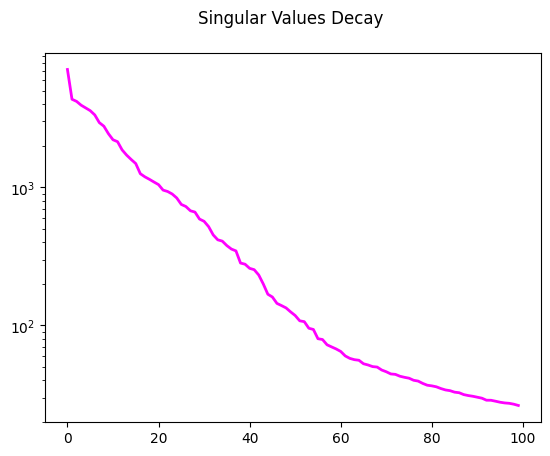

Residual energy of Surface elevation after keeping 100 modes: 0.0298 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])

Input shape for the model: 10
Output shape for the model: 100


In [54]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, imputer="last_value", verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True)

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training: 100%|██████████| 200/200 [02:32<00:00,  1.31it/s, Train Loss=0.02134, Val Loss=0.02718, Patience=3, Best Val Loss=0.02718, LR=0.00e+00]

Training completed with best validation loss: 0.0272


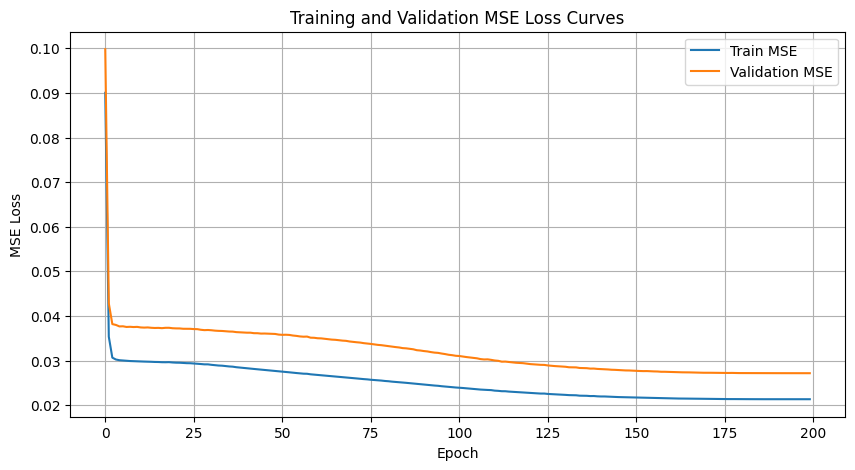

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017


In [55]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.1.C): last-value imputation for missing sensors"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

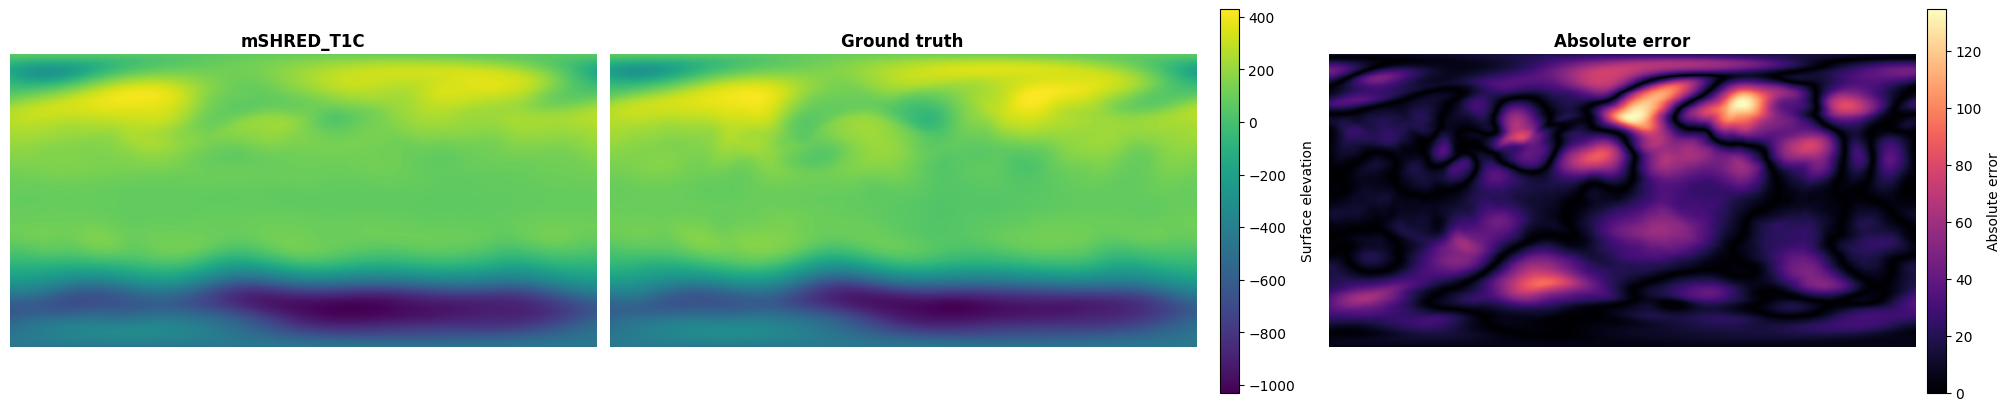

In [56]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T1C"
)
del train_dataset, val_dataset, test_dataset

## (T.2.A) GRUD

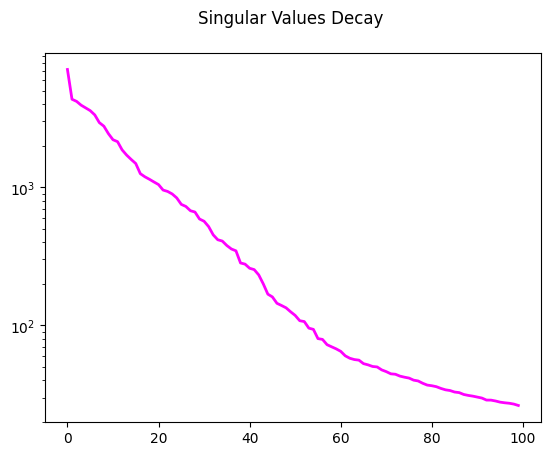

Residual energy of Surface elevation after keeping 100 modes: 0.0299 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 0

Data shapes after preparation:
Train:	 torch.Size([1512, 4, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 4, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 4, 100, 10]) -> torch.Size([252, 100])

Input shape for the model: 10
Output shape for the model: 100


In [60]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset, X_mean = manager.prepare(verbose=True, masking_type="grud")

# network input and output shapes
nn_input_shape = train_dataset[0][0].shape[-1]
nn_output_shape = train_dataset[0][1].shape[0]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training: 100%|██████████| 300/300 [05:58<00:00,  1.19s/it, Train Loss=0.02092, Val Loss=0.02888, Patience=0, Best Val Loss=0.02893, LR=2.50e-04] 

Training completed with best validation loss: 0.0289


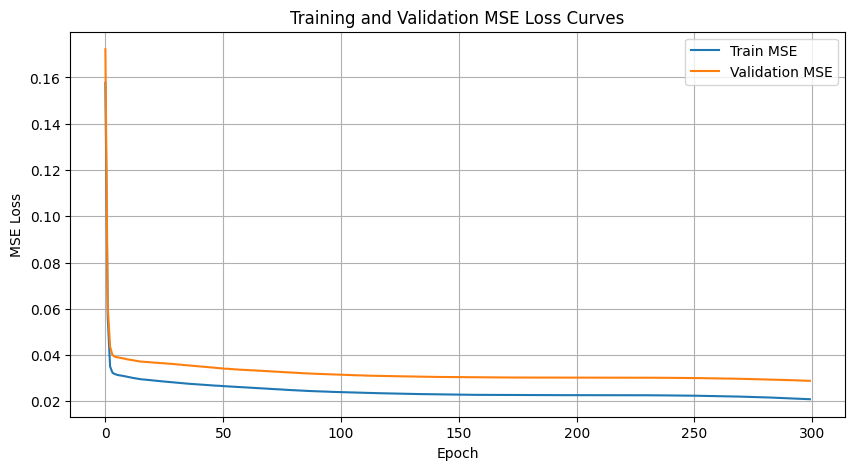

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140


In [61]:
# GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): GRUD+{DECODER}", type="(T.2.A): GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

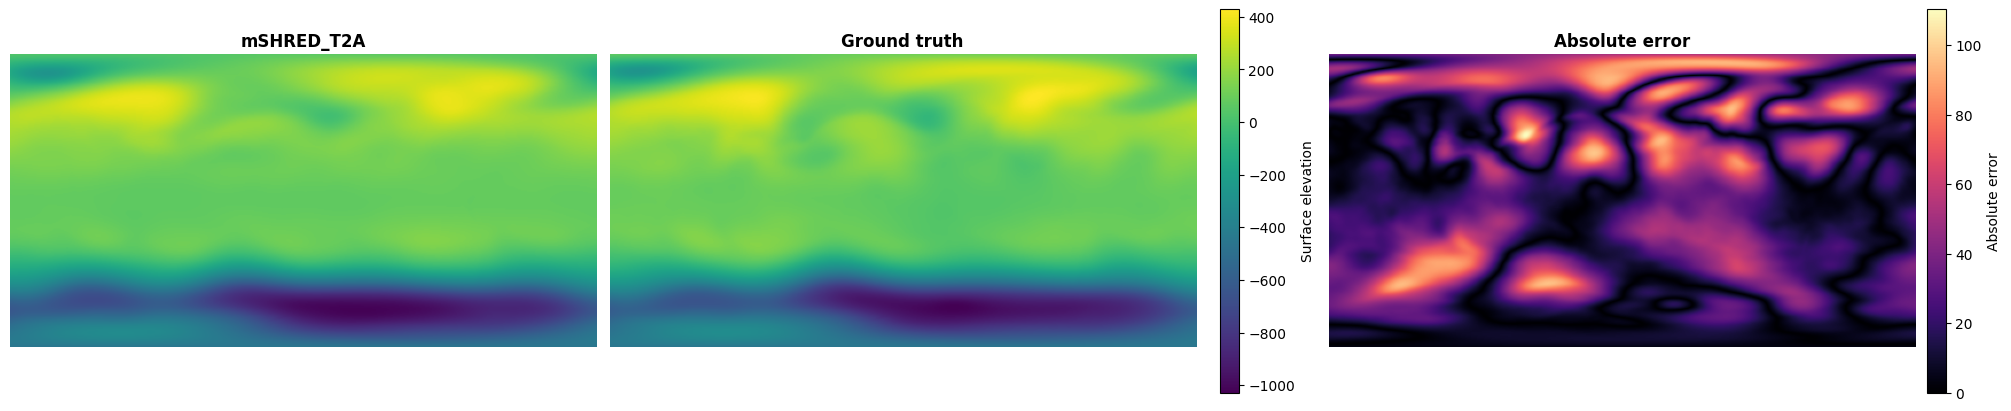

In [62]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T2A"
)

## (T.2.B): Attn-GRUD

Starting training...


Training: 100%|██████████| 300/300 [08:57<00:00,  1.79s/it, Train Loss=0.02243, Val Loss=0.02792, Patience=0, Best Val Loss=0.02795, LR=2.50e-04]

Training completed with best validation loss: 0.0279


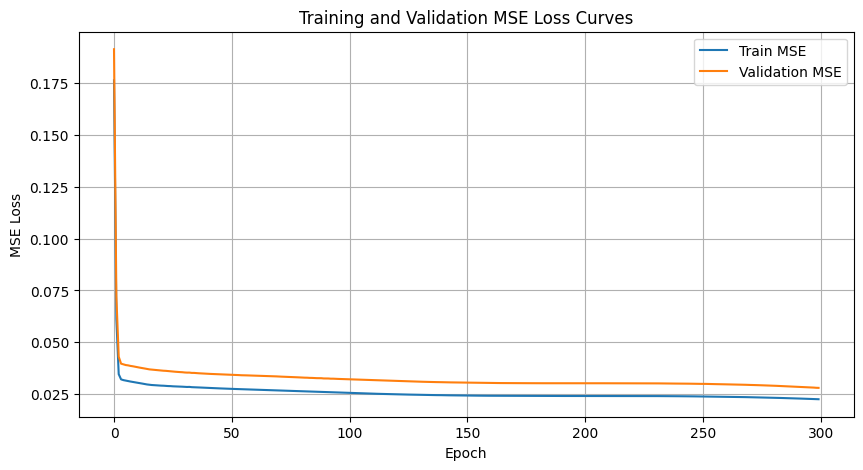

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450


In [63]:
# Attn-GRUD TRAINING
model_args = dict(
    # Encoder
    encoder="att_grud", input_size=nn_input_shape, hidden_size=HIDDEN_SIZE, X_mean=X_mean,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT,
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): Attn-GRUD+{DECODER}", type="(T.2.B): Attn-GRUD"
 )

ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

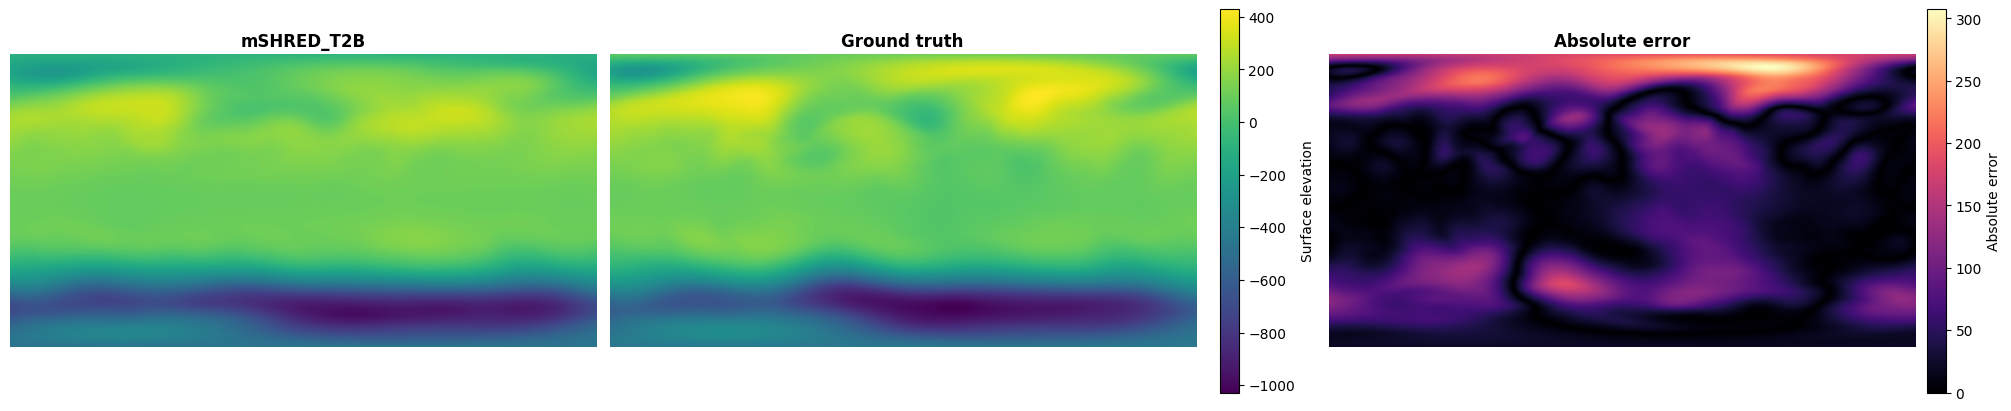

In [64]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T2B"
)
del train_dataset, val_dataset, test_dataset

## (T.3.A): Masking

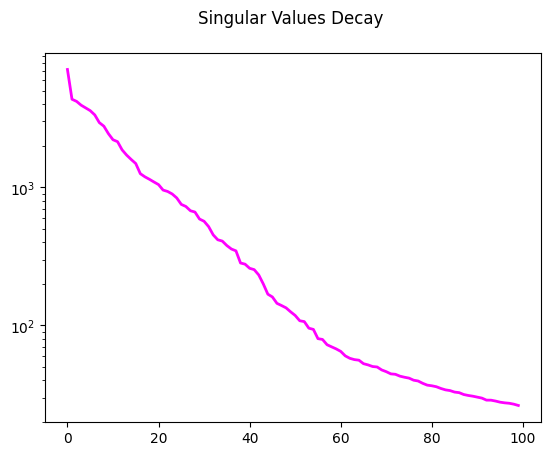

Residual energy of Surface elevation after keeping 100 modes: 0.0299 %

Datasets: ['Surface elevation']

Number of nan values in sensor measurements after masking: 4982

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 100])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 100])

Input shape for the model: 10
Output shape for the model: 100


In [65]:
# Data manager
NUM_EPOCHS = 300 
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

Starting training...


Training: 100%|██████████| 300/300 [03:38<00:00,  1.38it/s, Train Loss=0.01969, Val Loss=0.02697, Patience=0, Best Val Loss=0.02691, LR=2.50e-04]

Training completed with best validation loss: 0.0269


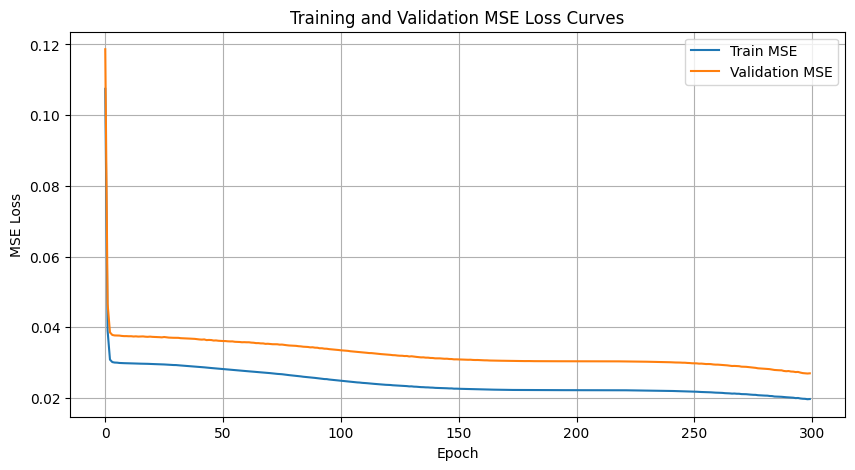

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172


In [66]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
)
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
)

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.A): masking", masking_type=MASKING_TYPE
)

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

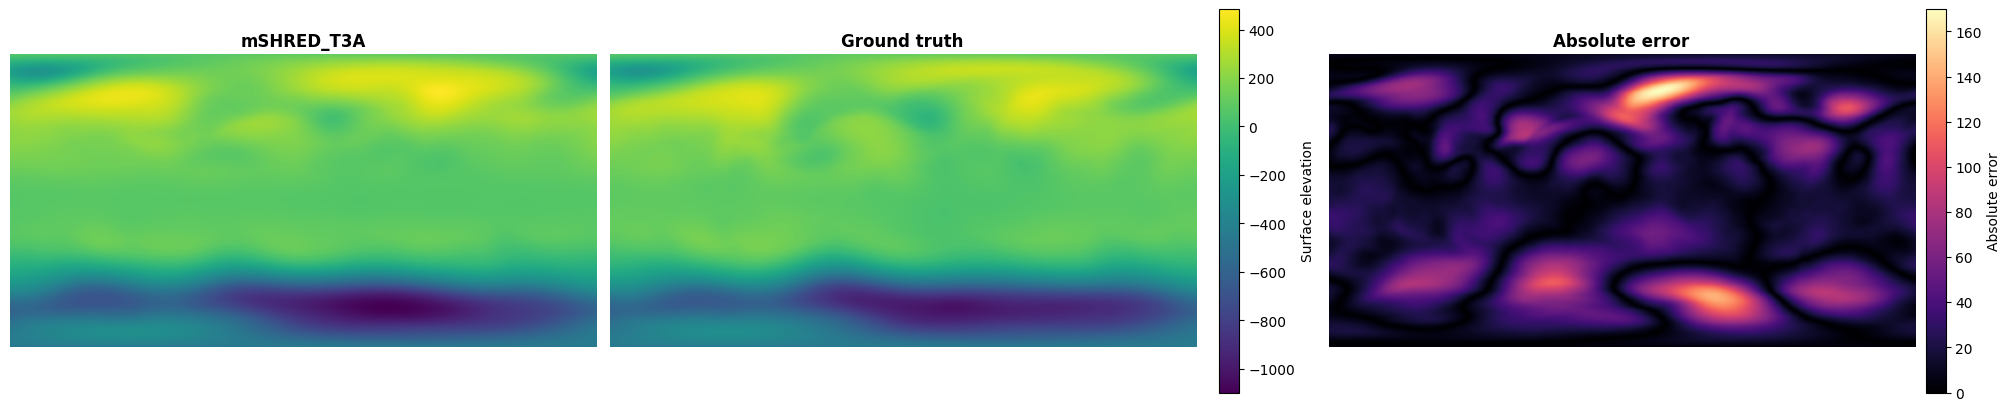

In [67]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3A"
)

## (T.3.B): Masking x2 channels

Starting training...


Training: 100%|██████████| 300/300 [03:40<00:00,  1.36it/s, Train Loss=0.01897, Val Loss=0.02460, Patience=0, Best Val Loss=0.02468, LR=2.50e-04] 

Training completed with best validation loss: 0.0246


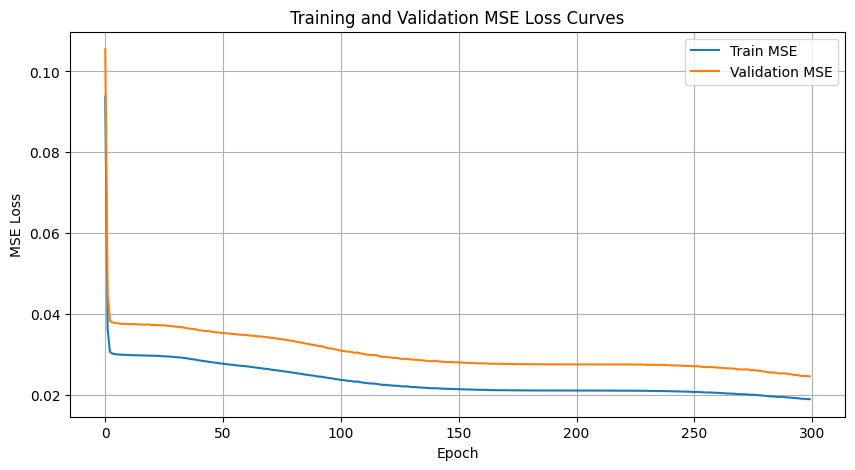

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606


In [68]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.B): masking x2 channels", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

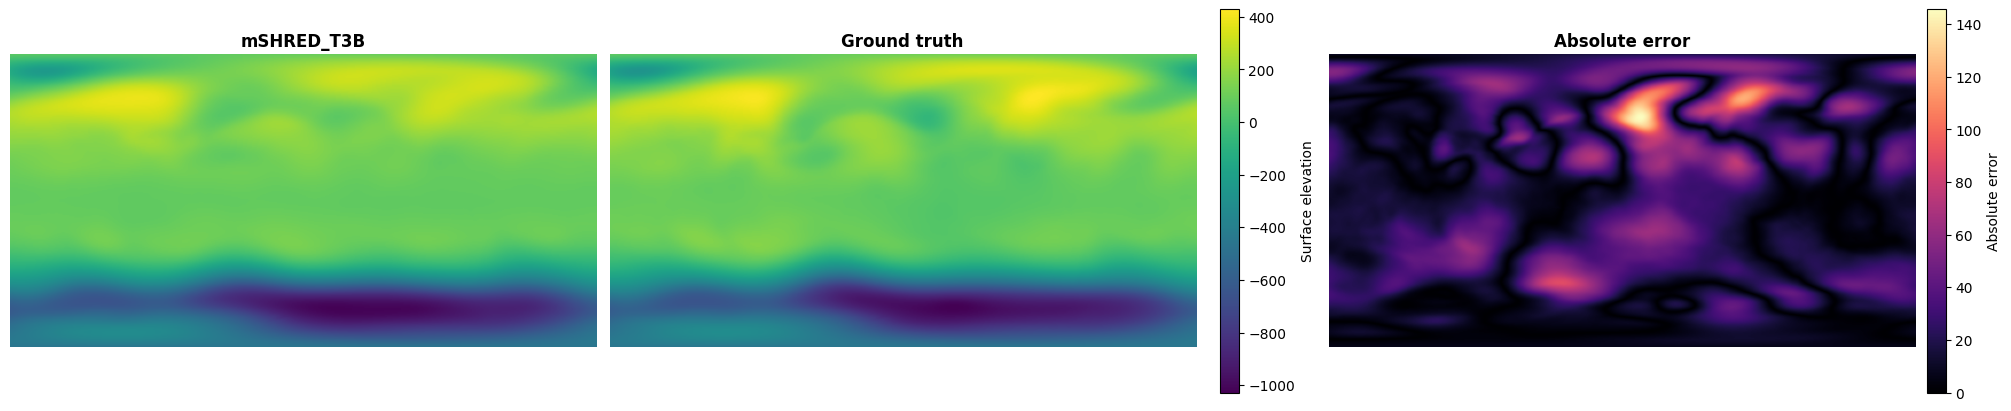

In [69]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3B"
)

## (T.3.C): Masking hidden space

Starting training...


Training: 100%|██████████| 300/300 [03:40<00:00,  1.36it/s, Train Loss=0.01984, Val Loss=0.02679, Patience=0, Best Val Loss=0.02680, LR=2.50e-04] 

Training completed with best validation loss: 0.0268


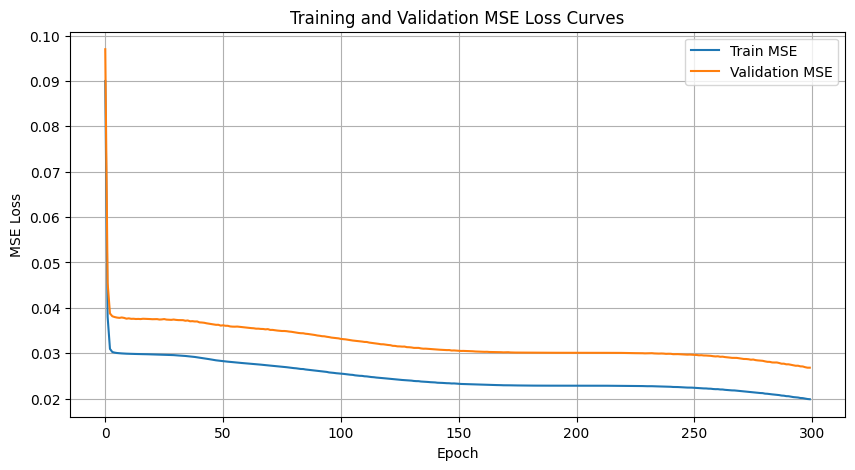

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.019842,0.026795,0.025345,0.281130,0.322696,0.313584,0.142463,0.161371,0.157071


In [70]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_hidden_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.C): masking hidden space", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

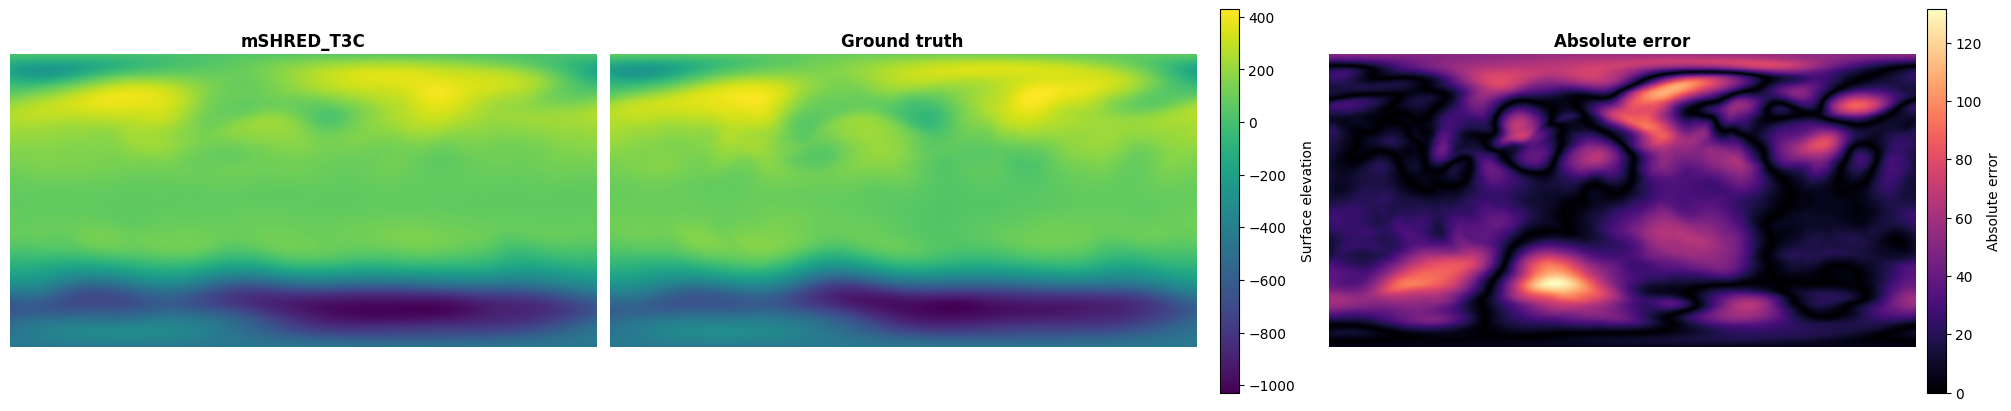

In [71]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3C"
)

## (T.3.D): Masking MHSA

Starting training...


Training: 100%|██████████| 300/300 [03:47<00:00,  1.32it/s, Train Loss=0.01980, Val Loss=0.02785, Patience=1, Best Val Loss=0.02803, LR=2.50e-04] 

Training completed with best validation loss: 0.0278


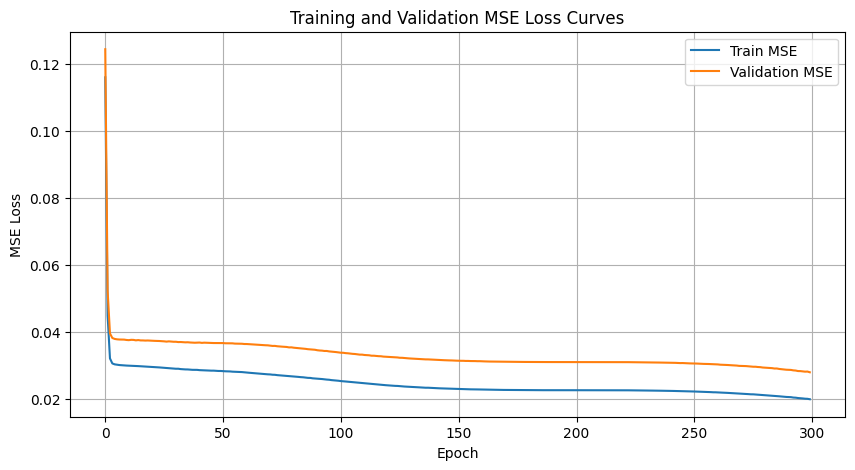

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.019842,0.026795,0.025345,0.281130,0.322696,0.313584,0.142463,0.161371,0.157071
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.019802,0.027847,0.025830,0.279559,0.328546,0.316099,0.142319,0.164508,0.158567


In [72]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=False,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.D): masking MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

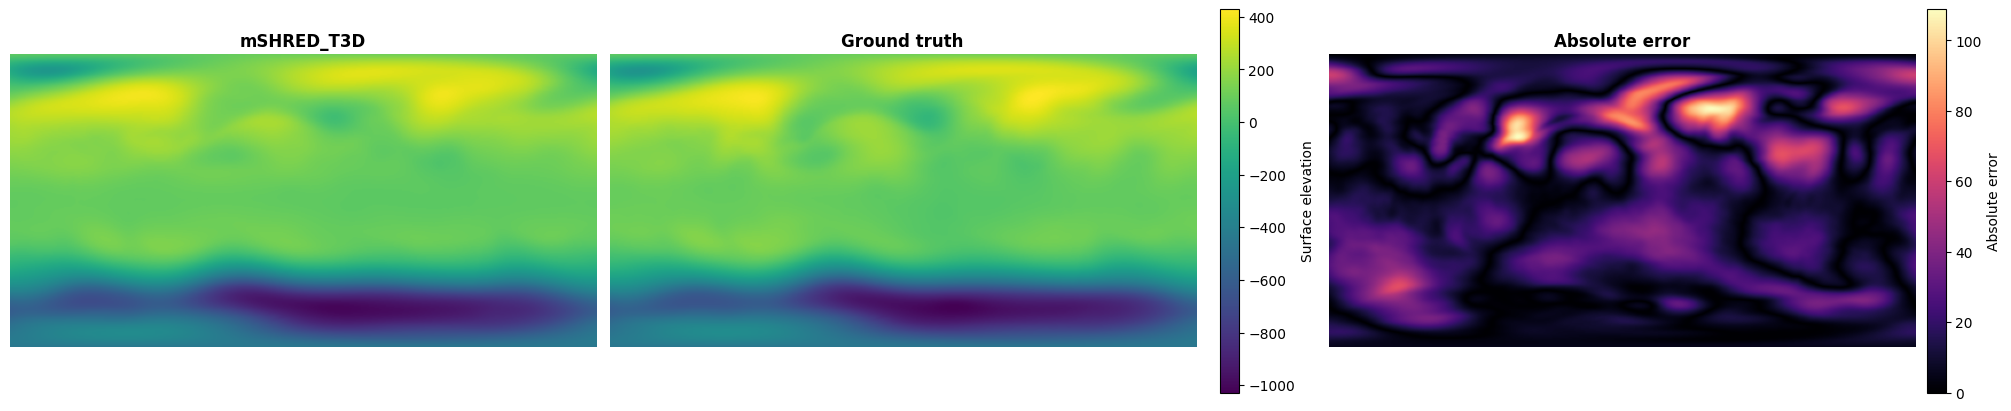

In [73]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3D"
)

## (T.3.E): Masking x2 channels + MHSA

Starting training...


Training: 100%|██████████| 300/300 [03:52<00:00,  1.29it/s, Train Loss=0.01967, Val Loss=0.02501, Patience=0, Best Val Loss=0.02504, LR=2.50e-04]

Training completed with best validation loss: 0.0250


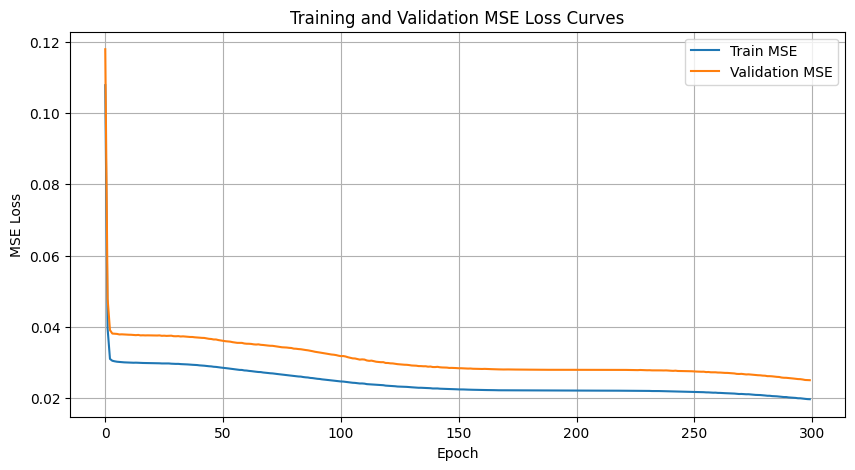

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.019842,0.026795,0.025345,0.281130,0.322696,0.313584,0.142463,0.161371,0.157071
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.019802,0.027847,0.025830,0.279559,0.328546,0.316099,0.142319,0.164508,0.158567
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.019672,0.025014,0.022942,0.280294,0.310547,0.297776,0.141853,0.155917,0.149440


In [74]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_attn_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.E): masking x2 channels + MHSA", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

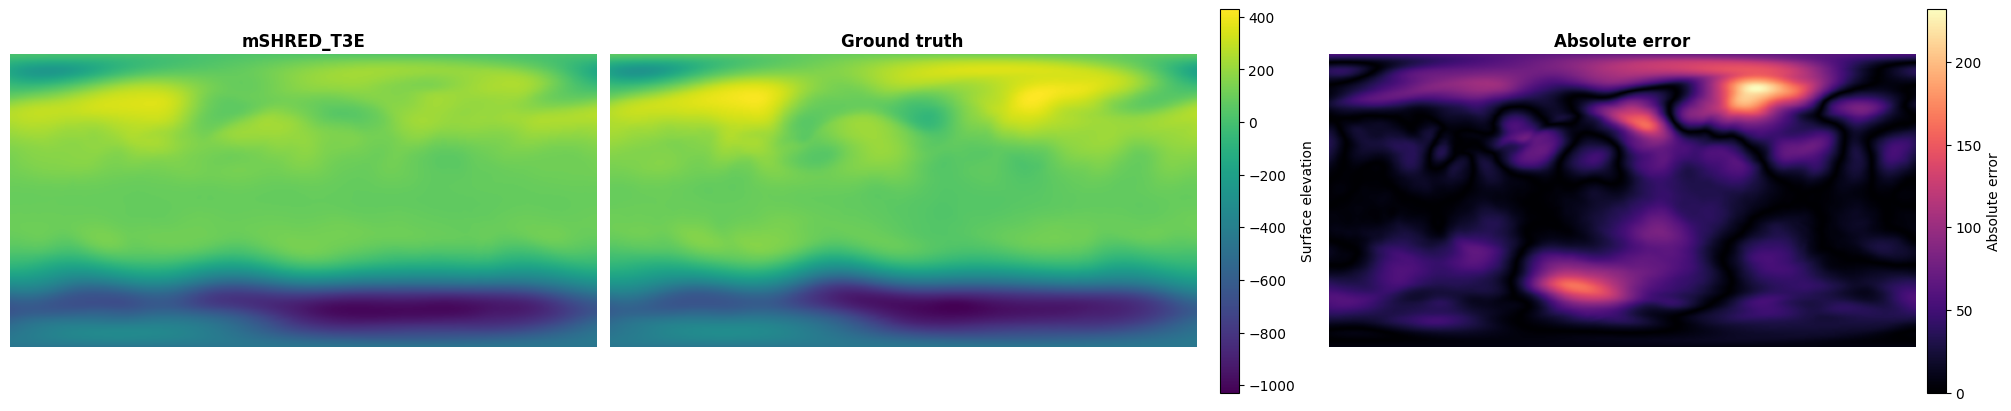

In [75]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3E"
)

## (T.3.F): Masking MHSA learned

Starting training...


Training: 100%|██████████| 300/300 [05:36<00:00,  1.12s/it, Train Loss=0.01937, Val Loss=0.02743, Patience=0, Best Val Loss=0.02750, LR=2.50e-04]

Training completed with best validation loss: 0.0274


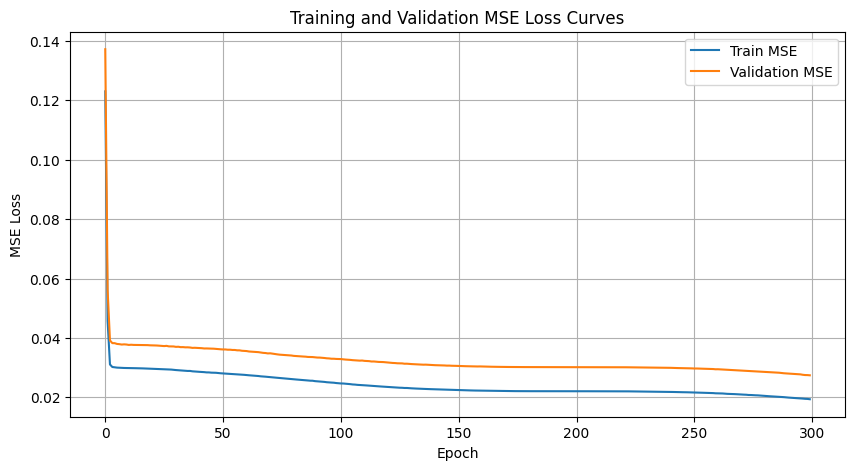

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.019842,0.026795,0.025345,0.281130,0.322696,0.313584,0.142463,0.161371,0.157071
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.019802,0.027847,0.025830,0.279559,0.328546,0.316099,0.142319,0.164508,0.158567
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.019672,0.025014,0.022942,0.280294,0.310547,0.297776,0.141853,0.155917,0.149440


In [76]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.F): masking MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

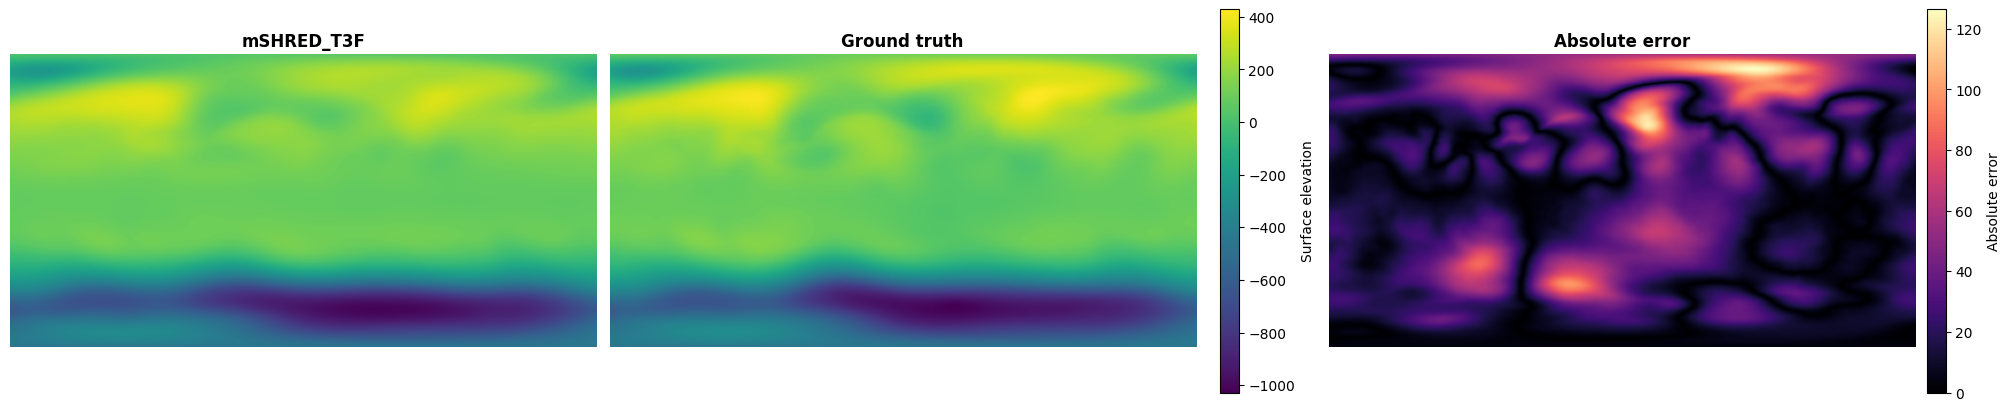

In [77]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3F"
)

## (T.3.G): Masking x2 channels + MHSA learned

Starting training...


Training: 100%|██████████| 300/300 [06:11<00:00,  1.24s/it, Train Loss=0.02127, Val Loss=0.02953, Patience=0, Best Val Loss=0.02961, LR=2.50e-04] 

Training completed with best validation loss: 0.0295


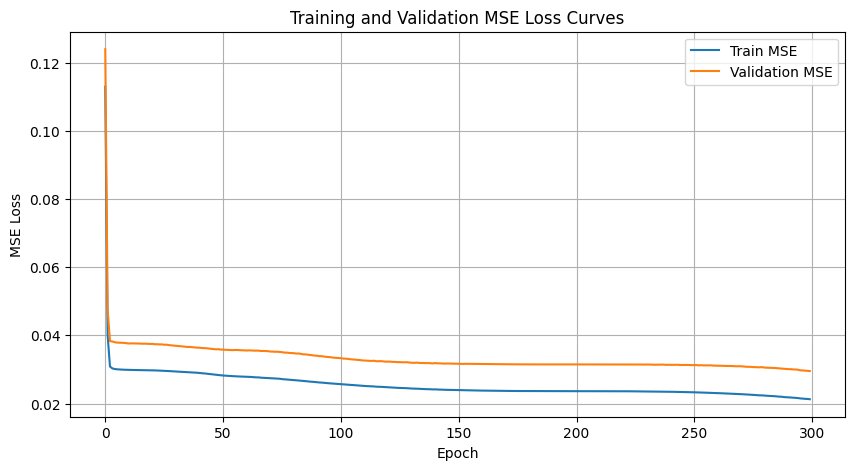

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.019842,0.026795,0.025345,0.281130,0.322696,0.313584,0.142463,0.161371,0.157071
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.019802,0.027847,0.025830,0.279559,0.328546,0.316099,0.142319,0.164508,0.158567
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.019672,0.025014,0.022942,0.280294,0.310547,0.297776,0.141853,0.155917,0.149440


In [78]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# Use cosine annealing LR schedule
train_errors, valid_errors = fit(
    mshred, train_dataset, val_dataset,
    optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
    lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
    masking_type=MASKING_TYPE,
 )

# PLOT TRAINING CURVES
plot_training_curves(train_errors, valid_errors)

# EVALUATION
test_error = evaluate_model(
    evaluate, mshred, train_dataset, val_dataset, test_dataset,
    model=f"(mSHRED): TR+{DECODER}", type="(T.3.G): masking x2 channels + MHSA learned", masking_type=MASKING_TYPE
 )

# Save errors to dataframe
ERRORS.append(test_error)
dataframe_errors = pd.DataFrame(ERRORS)
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

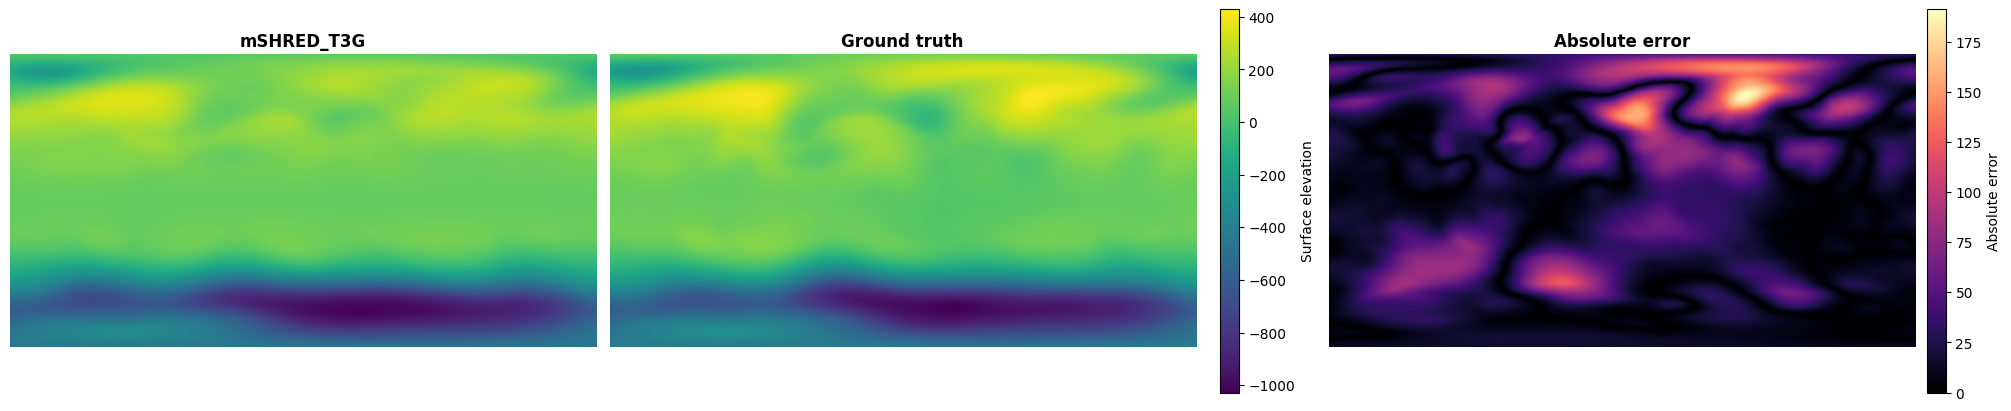

In [79]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

plot_reconstruction(
    test_reconstruction["Surface elevation"][-1],
    H[-1][-1],
    Lx, Ly,
    field_name="Surface elevation",
    title_prefix="mSHRED_T3G"
)

## Results

In [80]:
dataframe_errors = pd.read_csv("dataframe_errors.csv")  # reload to ensure clean data
display(dataframe_errors)
dataframe_errors.to_csv("dataframe_errors.csv", index=False)

,model,type,train-mse,val-mse,test-mse,train-mre,val-mre,test-mre,train-nrmse,val-nrmse,test-nrmse
0,(mSHRED): TR+cnn,(T.1.A): median imputation for missing sensors,0.022579,0.032223,0.028355,0.299326,0.353946,0.331944,0.151965,0.176962,0.166127
1,(mSHRED): TR+cnn,(T.1.B): mean imputation for missing sensors,0.021600,0.030292,0.028656,0.291958,0.342827,0.333499,0.148641,0.171584,0.167001
2,(mSHRED): TR+cnn,(T.1.C): last-value imputation for missing sen...,0.021345,0.027177,0.026660,0.291862,0.323837,0.321772,0.147687,0.162443,0.161017
3,(mSHRED): GRUD+cnn,(T.2.A): GRUD,0.020921,0.028875,0.026655,0.288390,0.334871,0.321873,0.146342,0.167584,0.161140
4,(mSHRED): Attn-GRUD+cnn,(T.2.B): Attn-GRUD,0.022431,0.027916,0.028784,0.300092,0.329592,0.334906,0.151533,0.164777,0.167450
5,(mSHRED): TR+cnn,(T.3.A): masking,0.019642,0.026913,0.025377,0.279734,0.323183,0.314148,0.141745,0.161725,0.157172
6,(mSHRED): TR+cnn,(T.3.B): masking x2 channels,0.018971,0.024601,0.023612,0.274856,0.308593,0.302720,0.139301,0.154623,0.151606
7,(mSHRED): TR+cnn,(T.3.C): masking hidden space,0.019842,0.026795,0.025345,0.281130,0.322696,0.313584,0.142463,0.161371,0.157071
8,(mSHRED): TR+cnn,(T.3.D): masking MHSA,0.019802,0.027847,0.025830,0.279559,0.328546,0.316099,0.142319,0.164508,0.158567
9,(mSHRED): TR+cnn,(T.3.E): masking x2 channels + MHSA,0.019672,0.025014,0.022942,0.280294,0.310547,0.297776,0.141853,0.155917,0.149440


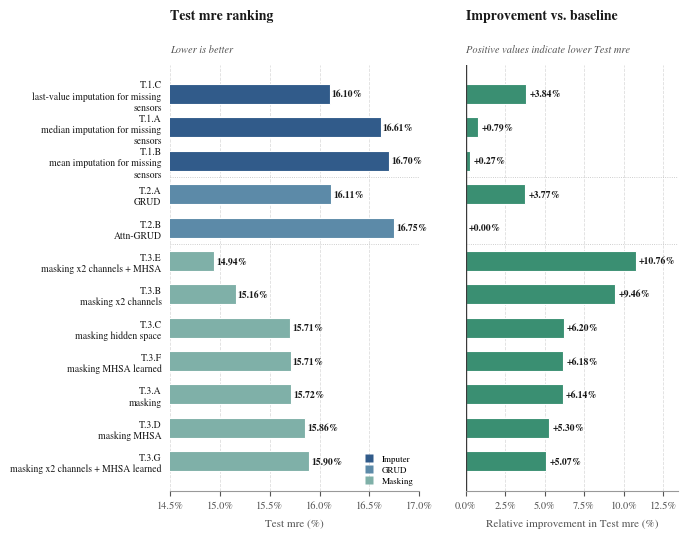

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import textwrap
from matplotlib.ticker import FuncFormatter

# ============================================================
# PAPER-READY SETTINGS
# ============================================================
# - Vector-safe fonts (Type 42) so PDF/EPS embed correctly in LaTeX
# - Serif font to match most journal body text (swap to sans if your
#   venue uses a sans-serif font, e.g. "DejaVu Sans" / "Arial")
# - White background (no off-white/slide-deck backdrop)
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "axes.unicode_minus": False,
})

# Set BASELINE_PATTERN to the substring identifying your baseline row
# (e.g. "T.0"). If no row matches, the code falls back to using the
# worst-performing (highest test-mre) row as the reference point.
BASELINE_PATTERN = "T.0"

# ============================================================
# LOAD DATA
# ============================================================

dataframe_errors = pd.read_csv("dataframe_errors.csv")

df_plot = dataframe_errors.copy()

# ------------------------------------------------------------
# Parse "(TAG): description" -> separate columns, and pull the
# ablation-group number out of the tag (T.1 / T.2 / T.3 / ...).
# Grouping keeps a long ablation table legible: rows are blocked
# by experiment family instead of one flat 13-row ranking.
# ------------------------------------------------------------
extracted = df_plot["type"].str.extract(r"^\(([^)]+)\):\s*(.*)$")
df_plot["tag"] = extracted[0].fillna(df_plot["type"])
df_plot["desc"] = extracted[1].fillna("")

df_plot["group"] = df_plot["tag"].str.extract(r"^T\.(\d+)").fillna("0")
group_order = sorted(df_plot["group"].unique(), key=lambda g: int(g))

df_plot = (
    df_plot
    .sort_values(["group", "test-nrmse"], ascending=[True, True])
    .reset_index(drop=True)
)

baseline_mask = df_plot["type"].str.contains(BASELINE_PATTERN, regex=False)

if baseline_mask.any():
    baseline_idx = df_plot.index[baseline_mask][0]
    baseline_test_mre = df_plot.loc[baseline_idx, "test-nrmse"]
else:
    baseline_idx = None
    baseline_test_mre = df_plot["test-nrmse"].max()

# Convert to percentage
df_plot["test-nrmse_%"] = 100 * df_plot["test-nrmse"]
df_plot["improvement_vs_baseline_%"] = (
    100 * (baseline_test_mre - df_plot["test-nrmse"]) / baseline_test_mre
)

# Wrap the description only (tag is shown separately via color), which
# keeps rows compact when there are many of them
df_plot["desc_wrapped"] = [
    "\n".join(textwrap.wrap(str(s), width=34))
    for s in df_plot["desc"]
]
df_plot["type_wrapped"] = df_plot["tag"] + "\n" + df_plot["desc_wrapped"]

n_models = len(df_plot)
y = np.arange(n_models)

# ============================================================
# STYLE — print-safe palette (also fine in grayscale)
# ============================================================

BLUE = "#315B8A"
GREEN = "#3A8F72"
RED = "#C65A54"
GOLD = "#D39B32"

TEXT = "#1A1A1A"
SECONDARY = "#555555"
GRID = "#DADADA"

# One color per ablation group (T.1 / T.2 / T.3 / ...), reused across
# both panels' left-side tick coloring so the reader can track a family
# of experiments down the whole table.
# Map each group number to a human-readable name for the legend; any
# group not listed here falls back to "Group N".
GROUP_NAMES = {
    "1": "Imputer",
    "2": "GRUD",
    "3": "Masking",
}
GROUP_PALETTE = ["#315B8A", "#5C8AA8", "#7FB0A8", "#A8A040", "#8A5C9E"]
group_colors = {
    g: GROUP_PALETTE[i % len(GROUP_PALETTE)]
    for i, g in enumerate(group_order)
}
group_labels = {
    g: GROUP_NAMES.get(g, f"Group {g}")
    for g in group_order
}

# ============================================================
# FIGURE — sized for a double-column journal figure
# (7.16 in is the standard IEEE/Elsevier two-column text width;
#  use 3.5 in single-column if you stack panels vertically instead)
# ============================================================

FIG_WIDTH_IN = 7.16
fig_height = max(2.6, 0.34 * n_models + 1.6)

fig, axes = plt.subplots(
    1, 2,
    figsize=(FIG_WIDTH_IN, fig_height),
    gridspec_kw={"width_ratios": [1.08, 0.92], "wspace": 0.20},
)
fig.patch.set_facecolor("white")
for ax in axes:
    ax.set_facecolor("white")


def add_panel_title(ax, title, subtitle):
    ax.text(0.0, 1.10, title, transform=ax.transAxes, fontsize=10,
             fontweight="bold", color=TEXT, ha="left", va="bottom")
    ax.text(0.0, 1.025, subtitle, transform=ax.transAxes, fontsize=7.5,
             color=SECONDARY, ha="left", va="bottom", style="italic")


# ============================================================
# LEFT PANEL — TEST MRE RANKING
# ============================================================

ax = axes[0]
bar_colors_left = [group_colors[g] for g in df_plot["group"]]
bars = ax.barh(y, df_plot["test-nrmse_%"], height=0.6, color=bar_colors_left,
                edgecolor="white", linewidth=0.8)

if baseline_idx is not None:
    bars[baseline_idx].set_color(GOLD)

ax.set_yticks(y)
ax.set_yticklabels(df_plot["type_wrapped"], fontsize=7, color=TEXT)
ax.invert_yaxis()

# Thin separators between ablation groups
group_boundaries = np.where(df_plot["group"].values[:-1] != df_plot["group"].values[1:])[0]
for b in group_boundaries:
    ax.axhline(b + 0.5, color="#BFBFBF", linewidth=0.6, linestyle=":", zorder=1)

add_panel_title(ax, "Test mre ranking", "Lower is better")
ax.set_xlabel("Test mre (%)", fontsize=8, color=SECONDARY, labelpad=6)

# Auto-range with a small margin instead of a hardcoded 12-15 window,
# so the script generalizes to other data
lo = np.floor(df_plot["test-nrmse_%"].min() * 4) / 4 - 0.25
hi = np.ceil(df_plot["test-nrmse_%"].max() * 4) / 4 + 0.25
ax.set_xlim(lo, hi)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for i, value in enumerate(df_plot["test-nrmse_%"]):
    ax.text(min(value + 0.02, hi - 0.04), i, f"{value:.2f}%", va="center",
             ha="left", fontsize=7, fontweight="bold", color=TEXT)

# Legend mapping group color -> group tag prefix (e.g. "T.1", "T.2")
legend_handles = [
    plt.Line2D([0], [0], marker="s", linestyle="none", markersize=6,
               markerfacecolor=group_colors[g], markeredgecolor="none",
               label=group_labels[g])
    for g in group_order
]
ax.legend(
    handles=legend_handles,
    loc="lower right",
    fontsize=6.5,
    frameon=False,
    handletextpad=0.4,
    labelspacing=0.3,
    borderaxespad=0.2,
)

# ============================================================
# RIGHT PANEL — IMPROVEMENT VS BASELINE
# ============================================================

ax = axes[1]
improvement = df_plot["improvement_vs_baseline_%"]

bar_colors = [
    GREEN if v > 1e-4 else RED if v < -1e-4 else "#8A8A8A"
    for v in improvement
]

ax.barh(y, improvement, height=0.6, color=bar_colors,
        edgecolor="white", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels([])
ax.invert_yaxis()
ax.axvline(0, color="#3A3A3A", linewidth=1.0, zorder=3)

for b in group_boundaries:
    ax.axhline(b + 0.5, color="#BFBFBF", linewidth=0.6, linestyle=":", zorder=1)

baseline_label = (
    df_plot.loc[baseline_idx, "type"] if baseline_idx is not None
    else "worst configuration"
)
add_panel_title(ax, "Improvement vs. baseline",
                 "Positive values indicate lower Test mre")
ax.set_xlabel("Relative improvement in Test mre (%)", fontsize=8,
              color=SECONDARY, labelpad=6)

ax.grid(axis="x", linestyle="--", linewidth=0.6, color=GRID, alpha=0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

max_positive = max(improvement.max(), 0.5)
max_negative = min(improvement.min(), 0)
ax.set_xlim(max_negative * 1.25, max_positive * 1.25)

max_abs = max(abs(improvement.min()), abs(improvement.max()), 0.5)
for i, value in enumerate(improvement):
    if value >= 0:
        ax.text(value + 0.02 * max_abs, i, f"+{value:.2f}%", va="center",
                 ha="left", fontsize=7, fontweight="bold", color=TEXT)
    else:
        ax.text(value - 0.02 * max_abs, i, f"{value:.2f}%", va="center",
                 ha="right", fontsize=7, fontweight="bold", color=TEXT)

# ============================================================
# AXIS CLEANUP
# ============================================================

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#999999")
    ax.tick_params(axis="y", length=0, pad=6)
    ax.tick_params(axis="x", colors=SECONDARY, labelsize=7.5)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.1f}%"))

if baseline_idx is not None:
    tick = axes[0].get_yticklabels()[baseline_idx]
    tick.set_fontweight("bold")
    tick.set_color("#9A711E")

# No in-image suptitle/caption text: papers caption figures via
# \caption{...} in LaTeX. If you want a caption note in the image
# anyway (e.g. for a slide reuse), uncomment below:
#
# fig.text(0.01, 0.01, f"Baseline: {baseline_label}", fontsize=6.5,
#           color=SECONDARY)

fig.subplots_adjust(top=0.88, bottom=0.13, left=0.27, right=0.98, wspace=0.22)


## Run1

<div>
<style scoped>
    .dataframe tbody tr th:only-of-type {
        vertical-align: middle;
    }

    .dataframe tbody tr th {
        vertical-align: top;
    }

    .dataframe thead th {
        text-align: right;
    }
</style>
<table border="1" class="dataframe">
  <thead>
    <tr style="text-align: right;">
      <th></th>
      <th>model</th>
      <th>type</th>
      <th>train-mse</th>
      <th>val-mse</th>
      <th>test-mse</th>
      <th>train-mre</th>
      <th>val-mre</th>
      <th>test-mre</th>
      <th>train-nrmse</th>
      <th>val-nrmse</th>
      <th>test-nrmse</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <th>0</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.A): median imputation for missing sensors</td>
      <td>0.022579</td>
      <td>0.032223</td>
      <td>0.028355</td>
      <td>0.299326</td>
      <td>0.353946</td>
      <td>0.331944</td>
      <td>0.151965</td>
      <td>0.176962</td>
      <td>0.166127</td>
    </tr>
    <tr>
      <th>1</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.B): mean imputation for missing sensors</td>
      <td>0.021600</td>
      <td>0.030292</td>
      <td>0.028656</td>
      <td>0.291958</td>
      <td>0.342827</td>
      <td>0.333499</td>
      <td>0.148641</td>
      <td>0.171584</td>
      <td>0.167001</td>
    </tr>
    <tr>
      <th>2</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.1.C): last-value imputation for missing sen...</td>
      <td>0.021345</td>
      <td>0.027177</td>
      <td>0.026660</td>
      <td>0.291862</td>
      <td>0.323837</td>
      <td>0.321772</td>
      <td>0.147687</td>
      <td>0.162443</td>
      <td>0.161017</td>
    </tr>
    <tr>
      <th>3</th>
      <td>(mSHRED): GRUD+cnn</td>
      <td>(T.2.A): GRUD</td>
      <td>0.020921</td>
      <td>0.028875</td>
      <td>0.026655</td>
      <td>0.288390</td>
      <td>0.334871</td>
      <td>0.321873</td>
      <td>0.146342</td>
      <td>0.167584</td>
      <td>0.161140</td>
    </tr>
    <tr>
      <th>4</th>
      <td>(mSHRED): Attn-GRUD+cnn</td>
      <td>(T.2.B): Attn-GRUD</td>
      <td>0.022431</td>
      <td>0.027916</td>
      <td>0.028784</td>
      <td>0.300092</td>
      <td>0.329592</td>
      <td>0.334906</td>
      <td>0.151533</td>
      <td>0.164777</td>
      <td>0.167450</td>
    </tr>
    <tr>
      <th>5</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.A): masking</td>
      <td>0.019642</td>
      <td>0.026913</td>
      <td>0.025377</td>
      <td>0.279734</td>
      <td>0.323183</td>
      <td>0.314148</td>
      <td>0.141745</td>
      <td>0.161725</td>
      <td>0.157172</td>
    </tr>
    <tr>
      <th>6</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.B): masking x2 channels</td>
      <td>0.018971</td>
      <td>0.024601</td>
      <td>0.023612</td>
      <td>0.274856</td>
      <td>0.308593</td>
      <td>0.302720</td>
      <td>0.139301</td>
      <td>0.154623</td>
      <td>0.151606</td>
    </tr>
    <tr>
      <th>7</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.C): masking hidden space</td>
      <td>0.019842</td>
      <td>0.026795</td>
      <td>0.025345</td>
      <td>0.281130</td>
      <td>0.322696</td>
      <td>0.313584</td>
      <td>0.142463</td>
      <td>0.161371</td>
      <td>0.157071</td>
    </tr>
    <tr>
      <th>8</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.D): masking MHSA</td>
      <td>0.019802</td>
      <td>0.027847</td>
      <td>0.025830</td>
      <td>0.279559</td>
      <td>0.328546</td>
      <td>0.316099</td>
      <td>0.142319</td>
      <td>0.164508</td>
      <td>0.158567</td>
    </tr>
    <tr>
      <th>9</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.E): masking x2 channels + MHSA</td>
      <td>0.019672</td>
      <td>0.025014</td>
      <td>0.022942</td>
      <td>0.280294</td>
      <td>0.310547</td>
      <td>0.297776</td>
      <td>0.141853</td>
      <td>0.155917</td>
      <td>0.149440</td>
    </tr>
    <tr>
      <th>10</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.F): masking MHSA learned</td>
      <td>0.019372</td>
      <td>0.027428</td>
      <td>0.025353</td>
      <td>0.276332</td>
      <td>0.326152</td>
      <td>0.312692</td>
      <td>0.140766</td>
      <td>0.163266</td>
      <td>0.157096</td>
    </tr>
    <tr>
      <th>11</th>
      <td>(mSHRED): TR+cnn</td>
      <td>(T.3.G): masking x2 channels + MHSA learned</td>
      <td>0.021271</td>
      <td>0.029528</td>
      <td>0.025959</td>
      <td>0.290496</td>
      <td>0.338203</td>
      <td>0.317197</td>
      <td>0.147503</td>
      <td>0.169402</td>
      <td>0.158962</td>
    </tr>
  </tbody>
</table>
</div>

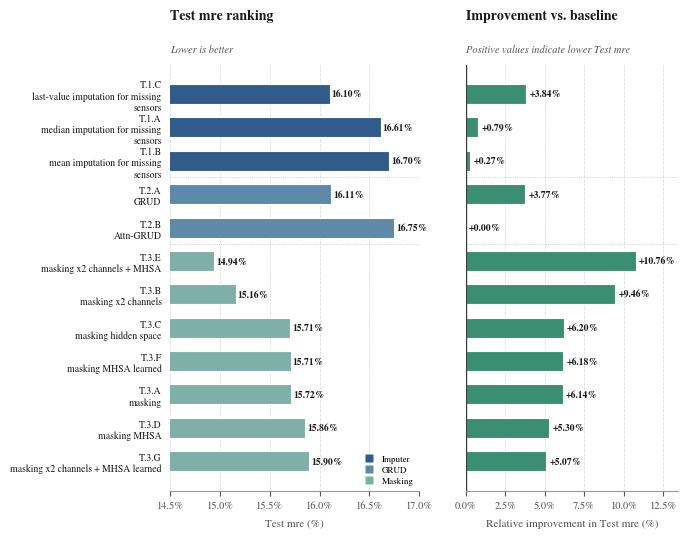